In [1]:
import numpy as np
from helpers import *
from implementations import * 


DATA_PATH = "./dataset/"

### Loading data

In [2]:
# Load data from CSV files
print("Loading data...")
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_PATH)
print("Data loaded")

print("Negative class rate:", np.mean(y_train == -1))
print("Positive class rate:", np.mean(y_train == 1))

Loading data...
Data loaded
Negative class rate: 0.911697929205967
Positive class rate: 0.08830207079403295


There is a strong imbalance in the dataset. Only about 8.8 % of examples are positive.

A model that predicts every example as negative might get very high accuracy, but the positive-class F1 score would be very low. 

### Preprocessing of data

Before applying a model to our data, it first needs to be preprocessed. 

We start by performing one-hot encoding to address the problem of categorical features. A linear model treats categories  (e.g. $1, 2, 3, 4, 5$) as numbers, implying that category $5$ is "five times greater" than category $1$. One-hot encoding turns them into independent binary values, allowing  logistic regression weights ($w$) to learn a distinct coefficient for each specific category independently.

We then search for columns in the training set with a percentage of Nan values higher than 90%, because we assume that a too high percentage of missing values makes them irrelevant. These columns are removed in both the training and test data sets, because the model must be trained and evaluated using the same features.

In the remaining columns, Nan values are replaced by column medians. Column medians are chosen over column means, because medians are typically less sensitive to outliers than means. The medians are calculated using the training set only, then those same medians are used to fill missing values in both the training and the test set. This prevents data leakage from the test set into the training process.

The standardization parameters (mean, standard deviation) are calculated based on the training set. Then the features of both the training and the test sets are Z-normalized by removing the mean and dividing by the standard deviation. Again, only training statistics are used for both datasets to avoid influence of the test set on prepropressing and assuring consistency.

Finally, a column of 1s is added at the beginning of the training and test sets to account for the bias term (w0, intercept) in our model.

### Possible values for the hypervariables

In [3]:
# Hypervariables
nan_thresholds = [0.60, 0.70, 0.80, 0.85, 0.90, 0.95]
regularizers = [0, 1e-5, 1e-4, 5e-4, 1e-3, 5e-3]    # lambda values to try (0 = no regularization)
iteration_checkpoints = [100, 200, 300, 400, 500]   # numbers of iterations to try
learning_rates = [0.1, 0.3, 0.5, 0.8]
decision_thresholds = np.arange(0.05, 0.91, 0.01)   # wider range: weighted models need higher thresholds

In [4]:
nan_threshold = 0.70
regularizer = 0.0005
iterations = 300
learning_rate = 0.5
sgd_learning_rate = 0.05   # step size of the mini-batch SGD used in the cross-validation section


def print_best_thresholds(results, n=5):
    """Print the n best rows returned by find_best_threshold."""
    print("F1       Threshold  Precision  Recall  Accuracy")
    for row in results[:n]:
        print(
            f'{row["F1"]:.4f}   {row["Threshold"]:.2f}       '
            f'{row["Precision"]:.4f}     {row["Recall"]:.4f}  {row["Accuracy"]:.4f}'
        )


### 1. Experiment - Compare performance and choose threshold

### 1.1. Experiment A : Logistic regression on non-weighted datasets

In [5]:
# 1. Split the original data BEFORE preprocessing
rng = np.random.default_rng(42)
indices = rng.permutation(len(y_train))

# 80% train, 20% validation
split = int(0.8 * len(indices))
train_idx = indices[:split]
val_idx = indices[split:]

x_tr_raw = x_train[train_idx] 
x_val_raw = x_train[val_idx] 

y_tr = y_train[train_idx]  
y_val = y_train[val_idx]

# 2. Fit preprocessing on training data only, with a given Nan threshold 

# Evaluate different Nan thresholds
for nan_thr in nan_thresholds:    # (renamed: the old loop variable overwrote nan_threshold)
    x_tr, x_val = preprocess_data(
        x_tr_raw, x_val_raw, nan_thr
    )

    # Convert labels from {-1, +1} to {0, 1}  (1-D arrays, as required by the project)
    y_tr_bin = np.where(y_tr == -1, 0, 1)
    y_val_bin = (y_val == 1).astype(int)


    # 3. Calculate class weights
    negative_rate = np.mean(y_tr_bin == 0)
    positive_rate = np.mean(y_tr_bin == 1)

    weight_negative = 1.0 / (2 * negative_rate)
    weight_positive = 1.0 / (2 * positive_rate)

    print("Training negative rate:", negative_rate)
    print("Training positive rate:", positive_rate)
    print("Negative class weight:", weight_negative)
    print("Positive class weight:", weight_positive)


    # 4. Train the same regularized logistic regression
    w_init = np.zeros(x_tr.shape[1])

    # Using non-weighted regularized logistic regression
    w_opt, loss = reg_logistic_regression(
        y_tr_bin,
        x_tr,
        regularizer,       
        w_init,
        iterations,          
        learning_rate        
    )

    # 5. Calculate validation probabilities
    probs = np.asarray(sigmoid(x_val @ w_opt)).ravel()

    # 6. Evaluate multiple decision thresholds (sorted by validation F1)
    results = find_best_threshold(y_val_bin, probs, decision_thresholds)

    print(f"\nNaN threshold {nan_thr} - best validation thresholds:")
    print_best_thresholds(results)


--- Starting Preprocessing ---
Number of removed columns with >60% NaNs: 129
Remaining features: 185
Smart-detected 101 true categorical columns out of 185.
Features shape after one-hot encoding: 517
Missing values replaced using medians from the training set.
Features standardized (zero mean, unit variance).
--- Starting Correlation Filtering ---


C:\Users\merle\AppData\Roaming\Python\Python312\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\merle\AppData\Roaming\Python\Python312\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Number of removed features due to high correlation: 140
Remaining features after filtering: 377
--- Correlation Filtering Complete ---

Final processed training shape: (262508, 378)
Final processed testing shape: (65627, 378)
--- Preprocessing Complete ---

Training negative rate: 0.9118122114373657
Training positive rate: 0.08818778856263428
Negative class weight: 0.5483585257229756
Positive class weight: 5.669719222462203

NaN threshold 0.6 - best validation thresholds:
F1       Threshold  Precision  Recall  Accuracy
0.4272   0.20       0.3488     0.5511  0.8688
0.4259   0.22       0.3668     0.5076  0.8785
0.4257   0.21       0.3565     0.5282  0.8735
0.4254   0.19       0.3392     0.5705  0.8632
0.4247   0.23       0.3756     0.4886  0.8825
--- Starting Preprocessing ---
Number of removed columns with >70% NaNs: 121
Remaining features: 193
Smart-detected 108 true categorical columns out of 193.
Features shape after one-hot encoding: 556
Missing values replaced using medians from th

### 1.2. Experiment B : Weighted logistic regression

In [6]:
# 1. Split the original data BEFORE preprocessing
rng = np.random.default_rng(42)
indices = rng.permutation(len(y_train))

# 80% train, 20% validation
split = int(0.8 * len(indices))
train_idx = indices[:split]
val_idx = indices[split:]

x_tr_raw = x_train[train_idx] 
x_val_raw = x_train[val_idx] 

y_tr = y_train[train_idx]  
y_val = y_train[val_idx]

# 2. Fit preprocessing on training data only, with a given Nan threshold 

# Evaluate different Nan thresholds
for nan_thr in nan_thresholds:    # (renamed: the old loop variable overwrote nan_threshold)
    x_tr, x_val = preprocess_data(
        x_tr_raw, x_val_raw, nan_thr
    )

    # Convert labels from {-1, +1} to {0, 1}  (1-D arrays, as required by the project)
    y_tr_bin = np.where(y_tr == -1, 0, 1)
    y_val_bin = (y_val == 1).astype(int)


    # 3. Calculate class weights
    negative_rate = np.mean(y_tr_bin == 0)
    positive_rate = np.mean(y_tr_bin == 1)

    weight_negative = 1.0 / (2 * negative_rate)
    weight_positive = 1.0 / (2 * positive_rate)

    print("Training negative rate:", negative_rate)
    print("Training positive rate:", positive_rate)
    print("Negative class weight:", weight_negative)
    print("Positive class weight:", weight_positive)


    # 4. Train the same regularized logistic regression
    w_init = np.zeros(x_tr.shape[1])

    # Using weighted regularized logistic regression
    w_opt, loss = weighted_reg_logistic_regression(
        y_tr_bin,
        x_tr,
        regularizer,       # regularization
        w_init,
        iterations,          # iterations
        learning_rate           # learning rate
    )

    # 5. Calculate validation probabilities
    probs = np.asarray(sigmoid(x_val @ w_opt)).ravel()

    # 6. Evaluate multiple decision thresholds (sorted by validation F1)
    results = find_best_threshold(y_val_bin, probs, decision_thresholds)

    print(f"\nNaN threshold {nan_thr} - best validation thresholds:")
    print_best_thresholds(results)


--- Starting Preprocessing ---
Number of removed columns with >60% NaNs: 129
Remaining features: 185
Smart-detected 101 true categorical columns out of 185.
Features shape after one-hot encoding: 517
Missing values replaced using medians from the training set.
Features standardized (zero mean, unit variance).
--- Starting Correlation Filtering ---
Number of removed features due to high correlation: 140
Remaining features after filtering: 377
--- Correlation Filtering Complete ---

Final processed training shape: (262508, 378)
Final processed testing shape: (65627, 378)
--- Preprocessing Complete ---

Training negative rate: 0.9118122114373657
Training positive rate: 0.08818778856263428
Negative class weight: 0.5483585257229756
Positive class weight: 5.669719222462203

NaN threshold 0.6 - best validation thresholds:
F1       Threshold  Precision  Recall  Accuracy
0.4274   0.72       0.3466     0.5573  0.8675
0.4265   0.71       0.3402     0.5715  0.8636
0.4259   0.70       0.3344     0.

### 1.3. Experiment C : Tuning the number of iterations, learning rate, regularizer and weighting

Experiments A and B use a single, guessed set of hyperparameters. Here we tune them one after the other on the same validation split (a coordinate search keeps the cost reasonable):

1. learning rate $\times$ number of iterations
2. regularizer $\lambda$ (together with the number of iterations)
3. weighted vs. non-weighted logistic regression
4. decision threshold, and a summary of how much each step improved the validation F1

Gradient descent has no memory, so training for 100 iterations and then continuing for 100 more from the returned $w$ is exactly the same as training for 200 iterations. One run therefore gives the whole *F1 vs. number of iterations* curve.

Note: with about 5'000 positive validation examples the F1 score has a standard error of roughly 0.003, so differences smaller than that are not meaningful.

In [22]:
# Preprocess once, on the training part of the hold-out split only
x_tr, x_val = preprocess_data(x_tr_raw, x_val_raw, nan_threshold)
y_tr_bin = np.where(y_tr == -1, 0, 1)
y_val_bin = (y_val == 1).astype(int)

TUNE_STEP = 1   # set to 2 (or 3) to tune on every 2nd (3rd) training row only: much faster
x_tune, y_tune = x_tr[::TUNE_STEP], y_tr_bin[::TUNE_STEP]


def train_and_evaluate(lambda_, lr, checkpoints, weighted=False):
    """Gradient descent, evaluated on the validation set after each number of iterations in `checkpoints`.

    Returns the list of results (best threshold, F1, ...) and the final weights.
    """
    train_fn = weighted_reg_logistic_regression if weighted else reg_logistic_regression
    w = np.zeros(x_tune.shape[1])
    done, rows = 0, []
    for n_iter in checkpoints:
        with np.errstate(all="ignore"):      # exp() overflow just saturates the sigmoid
            w, _ = train_fn(y_tune, x_tune, lambda_, w, n_iter - done, lr)   # continue from w
        done = n_iter
        probs = sigmoid_safe(x_val @ w)
        best = find_best_threshold(y_val_bin, probs, decision_thresholds)[0]   # best threshold by F1
        best["F1 @ 0.5"] = calculate_metrics(y_val_bin, probs, 0.5)["F1"]
        best["Iterations"] = n_iter
        rows.append(best)
    return rows, w


def print_grid(title, curves):
    """curves: {parameter value: list of results over the iteration checkpoints}"""
    print(title)
    print(f'{"":<9}' + "".join(f"{n:>9}" for n in iteration_checkpoints) + "    <- iterations")
    for param, rows in curves.items():
        print(f"{param:<9}" + "".join(f'{r["F1"]:>9.4f}' for r in rows))


def best_of(curves):
    """(parameter value, result row) with the highest validation F1."""
    return max(((p, r) for p, rows in curves.items() for r in rows), key=lambda t: t[1]["F1"])

--- Starting Preprocessing ---
Number of removed columns with >70% NaNs: 121
Remaining features: 193
Smart-detected 108 true categorical columns out of 193.
Features shape after one-hot encoding: 556
Missing values replaced using medians from the training set.
Features standardized (zero mean, unit variance).
--- Starting Correlation Filtering ---


C:\Users\merle\AppData\Roaming\Python\Python312\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\merle\AppData\Roaming\Python\Python312\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Number of removed features due to high correlation: 154
Remaining features after filtering: 402
--- Correlation Filtering Complete ---

Final processed training shape: (262508, 403)
Final processed testing shape: (65627, 403)
--- Preprocessing Complete ---



In [17]:
# Step 1: learning rate x number of iterations  (regularizer = default, non-weighted)
curves_lr = {lr: train_and_evaluate(regularizer, lr, iteration_checkpoints)[0] for lr in learning_rates}
print_grid(f"Validation F1 (at its best threshold), lambda = {regularizer}", curves_lr)

best_lr, row = best_of(curves_lr)
best_iters = row["Iterations"]
print(f"\n-> best learning rate: {best_lr}, iterations: {best_iters}  (F1 = {row['F1']:.4f})")

Validation F1 (at its best threshold), lambda = 0.0005
               100      200      300      400      500    <- iterations
0.1         0.4236   0.4253   0.4260   0.4268   0.4280
0.3         0.4259   0.4290   0.4288   0.4293   0.4299
0.5         0.4278   0.4287   0.4299   0.4295   0.4297
0.8         0.4287   0.4299   0.4299   0.4290   0.4289

-> best learning rate: 0.3, iterations: 500  (F1 = 0.4299)


In [18]:
# Step 2: regularizer lambda  (learning rate from step 1, non-weighted)
curves_lam = {lam: train_and_evaluate(lam, best_lr, iteration_checkpoints)[0] for lam in regularizers}
print_grid(f"Validation F1 (at its best threshold), lr = {best_lr}", curves_lam)

best_lam, row_lam = best_of(curves_lam)
best_iters = row_lam["Iterations"]
print(f"\n-> best lambda: {best_lam}, iterations: {best_iters}  (F1 = {row_lam['F1']:.4f})")

Validation F1 (at its best threshold), lr = 0.3
               100      200      300      400      500    <- iterations
0           0.4267   0.4288   0.4287   0.4287   0.4292
1e-05       0.4266   0.4289   0.4287   0.4287   0.4290
0.0001      0.4267   0.4290   0.4285   0.4291   0.4289
0.0005      0.4259   0.4290   0.4288   0.4293   0.4299
0.001       0.4259   0.4285   0.4286   0.4291   0.4285
0.005       0.4269   0.4274   0.4279   0.4290   0.4291

-> best lambda: 0.0005, iterations: 500  (F1 = 0.4299)


Weighted logistic regression
               100      200      300      400      500    <- iterations
weighted    0.4292   0.4282   0.4283   0.4280   0.4281

Non-weighted F1 = 0.4299 | weighted F1 = 0.4292  ->  use weighted: False

Best thresholds for the final model (lr=0.3, lambda=0.0005, iterations=500, weighted=False):
F1       Threshold  Precision  Recall  Accuracy
0.4299   0.20       0.3514     0.5535  0.8697
0.4283   0.22       0.3688     0.5106  0.8790
0.4279   0.19       0.3416     0.5727  0.8641
0.4277   0.23       0.3781     0.4922  0.8831
0.4274   0.21       0.3587     0.5286  0.8743


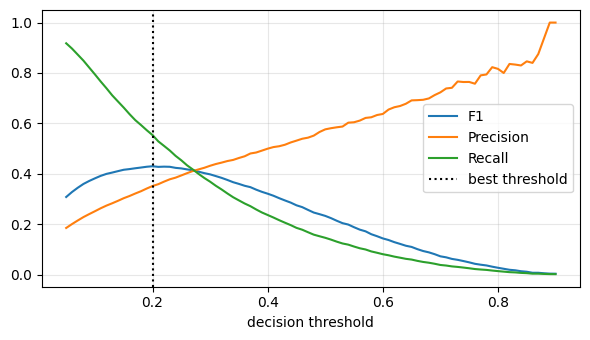


F1 at the best threshold: train = 0.4326, validation = 0.4299  (a large gap suggests overfitting; both low suggests underfitting)


In [19]:
# Step 3: weighted vs. non-weighted logistic regression (lr and lambda from steps 1-2)
curves_w = {"weighted": train_and_evaluate(best_lam, best_lr, iteration_checkpoints, weighted=True)[0]}
print_grid("Weighted logistic regression", curves_w)

_, row_w = best_of(curves_w)
use_weighted = row_w["F1"] > row_lam["F1"]
row_final = row_w if use_weighted else row_lam
best_iters = row_final["Iterations"]
print(f"\nNon-weighted F1 = {row_lam['F1']:.4f} | weighted F1 = {row_w['F1']:.4f}  ->  use weighted: {use_weighted}")

# Step 4: decision threshold of the final model
_, w_best = train_and_evaluate(best_lam, best_lr, [best_iters], weighted=use_weighted)
probs_val = sigmoid_safe(x_val @ w_best)
threshold_results = find_best_threshold(y_val_bin, probs_val, decision_thresholds)
best_thr = threshold_results[0]["Threshold"]
print(f"\nBest thresholds for the final model (lr={best_lr}, lambda={best_lam}, "
      f"iterations={best_iters}, weighted={use_weighted}):")
print_best_thresholds(threshold_results)

# F1, precision and recall as a function of the threshold
import matplotlib.pyplot as plt
by_thr = sorted(threshold_results, key=lambda r: r["Threshold"])
plt.figure(figsize=(6, 3.5))
for name in ("F1", "Precision", "Recall"):
    plt.plot([r["Threshold"] for r in by_thr], [r[name] for r in by_thr], label=name)
plt.axvline(best_thr, color="k", linestyle=":", label="best threshold")
plt.xlabel("decision threshold"); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# Overfitting / underfitting check: compare F1 on the training set and on the validation set
probs_tr = sigmoid_safe(x_tune @ w_best)
f1_tr = calculate_metrics(y_tune, probs_tr, best_thr)["F1"]
f1_va = calculate_metrics(y_val_bin, probs_val, best_thr)["F1"]
print(f"\nF1 at the best threshold: train = {f1_tr:.4f}, validation = {f1_va:.4f}  "
      "(a large gap suggests overfitting; both low suggests underfitting)")

In [20]:
# Summary: how much did each step improve the validation F1?
base_rows, _ = train_and_evaluate(regularizer, learning_rate, [iterations])   # the starting hyperparameters
steps = [
    ("Starting point (threshold 0.5)",           base_rows[0]["F1 @ 0.5"], 0.5),
    ("+ tuned decision threshold",               base_rows[0]["F1"],       base_rows[0]["Threshold"]),
    ("+ tuned learning rate and iterations",     best_of(curves_lr)[1]["F1"],  best_of(curves_lr)[1]["Threshold"]),
    ("+ tuned regularizer",                      row_lam["F1"],            row_lam["Threshold"]),
    ("+ class weighting" + ("" if use_weighted else " (not selected)"), row_final["F1"], row_final["Threshold"]),
]
print(f'{"Step":<45}{"Val F1":>8}{"Change":>9}{"Threshold":>11}')
previous = None
for name, f1, thr in steps:
    change = "" if previous is None else f"{f1 - previous:+.4f}"
    print(f"{name:<45}{f1:>8.4f}{change:>9}{thr:>11.2f}")
    previous = f1

Step                                           Val F1   Change  Threshold
Starting point (threshold 0.5)                 0.2329                0.50
+ tuned decision threshold                     0.4299  +0.1970       0.20
+ tuned learning rate and iterations           0.4299  +0.0000       0.20
+ tuned regularizer                            0.4299  +0.0000       0.20
+ class weighting (not selected)               0.4299  +0.0000       0.20


### 2. 5-fold cross-validation

In [23]:
# Convert original labels {-1, +1} to binary labels {0, 1}.
y_all_binary = np.where(
    np.asarray(y_train).ravel() == -1, 0, 1
)

X_raw = np.asarray(x_train)
n_folds = 5

folds = make_stratified_folds(
    y_all_binary, n_folds=n_folds, seed=42
)

# Each row receives one prediction from a model that did not train on it.
oof_normal = np.zeros(len(y_all_binary))
oof_weighted = np.zeros(len(y_all_binary))

for fold_num, val_idx in enumerate(folds, start=1):
    print(f"\n========== Fold {fold_num}/{n_folds} ==========")

    train_idx = np.setdiff1d(
        np.arange(len(y_all_binary)),
        val_idx,
        assume_unique=True
    )

    X_fold_train_raw = X_raw[train_idx]
    X_fold_val_raw = X_raw[val_idx]

    y_fold_train = y_all_binary[train_idx]
    y_fold_val = y_all_binary[val_idx]

    # Fit preprocessing only on this fold's training data.
    X_fold_train, X_fold_val = preprocess_data(
        X_fold_train_raw,
        X_fold_val_raw,
        nan_threshold=nan_threshold
    )

    print("Training normal SGD...")
    w_normal = train_logistic_sgd(
        y_fold_train,
        X_fold_train,
        lambda_=regularizer,
        learning_rate=sgd_learning_rate,
        epochs=12,
        batch_size=2048,
        weighted=False,
        seed=100 + fold_num
    )

    print("Training weighted SGD...")
    w_weighted = train_logistic_sgd(
        y_fold_train,
        X_fold_train,
        lambda_=regularizer,
        learning_rate=sgd_learning_rate,
        epochs=12,
        batch_size=2048,
        weighted=True,
        seed=100 + fold_num
    )

    # Save probabilities for the held-out fold.
    oof_normal[val_idx] = sigmoid_safe(
        X_fold_val @ w_normal
    ).ravel()

    oof_weighted[val_idx] = sigmoid_safe(
        X_fold_val @ w_weighted
    ).ravel()

    print(
        f"Fold {fold_num} complete. "
        f"Validation rows: {len(val_idx):,}"
    )

print("\nCross-validation predictions are ready.")


========== Fold 1/5 ==========
--- Starting Preprocessing ---
Number of removed columns with >70% NaNs: 121
Remaining features: 193
Smart-detected 106 true categorical columns out of 193.
Features shape after one-hot encoding: 553
Missing values replaced using medians from the training set.
Features standardized (zero mean, unit variance).
--- Starting Correlation Filtering ---
Number of removed features due to high correlation: 152
Remaining features after filtering: 401
--- Correlation Filtering Complete ---

Final processed training shape: (262508, 402)
Final processed testing shape: (65627, 402)
--- Preprocessing Complete ---

Training normal SGD...
Training weighted SGD...
Fold 1 complete. Validation rows: 65,627

========== Fold 2/5 ==========
--- Starting Preprocessing ---
Number of removed columns with >70% NaNs: 121
Remaining features: 193
Smart-detected 106 true categorical columns out of 193.
Features shape after one-hot encoding: 552
Missing values replaced using medians f

### 4. Compare F1, precision, and recall

In [24]:
normal_results = find_best_threshold(
    y_all_binary, oof_normal, decision_thresholds
)
weighted_results = find_best_threshold(
    y_all_binary, oof_weighted, decision_thresholds
)

print("NORMAL SGD — best thresholds")
print("F1       Threshold  Precision  Recall  Accuracy")
for row in normal_results[:10]:
    print(
        f'{row["F1"]:.4f}   '
        f'{row["Threshold"]:.2f}       '
        f'{row["Precision"]:.4f}     '
        f'{row["Recall"]:.4f}  '
        f'{row["Accuracy"]:.4f}'
    )

print("\nWEIGHTED SGD — best thresholds")
print("F1       Threshold  Precision  Recall  Accuracy")
for row in weighted_results[:10]:
    print(
        f'{row["F1"]:.4f}   '
        f'{row["Threshold"]:.2f}       '
        f'{row["Precision"]:.4f}     '
        f'{row["Recall"]:.4f}  '
        f'{row["Accuracy"]:.4f}'
    )

NORMAL SGD — best thresholds
F1       Threshold  Precision  Recall  Accuracy
0.4239   0.21       0.3525     0.5317  0.8724
0.4238   0.20       0.3434     0.5532  0.8671
0.4230   0.19       0.3345     0.5753  0.8614
0.4225   0.22       0.3610     0.5093  0.8771
0.4213   0.18       0.3249     0.5991  0.8547
0.4213   0.23       0.3701     0.4890  0.8814
0.4199   0.17       0.3162     0.6248  0.8476
0.4187   0.24       0.3783     0.4688  0.8851
0.4154   0.16       0.3057     0.6481  0.8389
0.4152   0.25       0.3862     0.4488  0.8883

WEIGHTED SGD — best thresholds
F1       Threshold  Precision  Recall  Accuracy
0.4250   0.73       0.3539     0.5319  0.8729
0.4248   0.72       0.3474     0.5467  0.8693
0.4245   0.71       0.3410     0.5622  0.8654
0.4239   0.74       0.3598     0.5157  0.8762
0.4238   0.70       0.3349     0.5768  0.8615
0.4229   0.69       0.3294     0.5907  0.8577
0.4229   0.75       0.3665     0.4997  0.8796
0.4215   0.68       0.3235     0.6045  0.8535
0.4215   0.76  

### 5. Select the winner and train on all labeled data

In [26]:
# Select the model with the highest out-of-fold F1.
best_normal = normal_results[0]
best_weighted = weighted_results[0]

if best_weighted["F1"] > best_normal["F1"]:
    chosen_model = "weighted"
    best_result = best_weighted
else:
    chosen_model = "normal"
    best_result = best_normal

best_threshold = best_result["Threshold"]

print("Selected model:", chosen_model)
print("Selected OOF threshold:", best_threshold)
print("Best OOF F1:", round(best_result["F1"], 4))

# Fit preprocessing on all labeled training rows.
X_full, X_test_proc = preprocess_data(
    x_train, x_test, nan_threshold=0.95
)

# Retrain the selected model on all labeled examples.
w_final = train_logistic_sgd(
    y_all_binary,
    X_full,
    lambda_=regularizer,
    learning_rate=sgd_learning_rate,
    epochs=12,
    batch_size=2048,
    weighted=(chosen_model == "weighted"),
    seed=42
)

# Predict probabilities, then convert back to {-1, +1}.
test_probabilities = sigmoid_safe(
    X_test_proc @ w_final
).ravel()

test_predictions = np.where(
    test_probabilities >= best_threshold, 1, -1
)

print("Positive test predictions:", np.sum(test_predictions == 1))
print("Negative test predictions:", np.sum(test_predictions == -1))

create_csv_submission(
    test_ids,
    test_predictions,
    "sgd_logistic_submission.csv"
)

print("Submission file created: sgd_logistic_submission.csv")

Selected model: weighted
Selected OOF threshold: 0.73
Best OOF F1: 0.425
--- Starting Preprocessing ---
Number of removed columns with >95% NaNs: 68
Remaining features: 246
Smart-detected 136 true categorical columns out of 246.
Features shape after one-hot encoding: 740
Missing values replaced using medians from the training set.
Features standardized (zero mean, unit variance).
--- Starting Correlation Filtering ---


C:\Users\merle\AppData\Roaming\Python\Python312\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\merle\AppData\Roaming\Python\Python312\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Number of removed features due to high correlation: 173
Remaining features after filtering: 567
--- Correlation Filtering Complete ---

Final processed training shape: (328135, 568)
Final processed testing shape: (109379, 568)
--- Preprocessing Complete ---

Positive test predictions: 14594
Negative test predictions: 94785
Submission file created: sgd_logistic_submission.csv


### Determination of model overfits or underfits

Underfitting
- Symptoms : 
    - High training loss / low training F1
    - High validation loss / low validation F1
- Causes : 
    - Model too simple
    - Regularization (lambda) too high
    - Not enough training iterations

Overfitting
- Symptoms : 
    - Very low training loss / high training F1
    - High validation loss / low validation F1
- Causes :
    - Model too complex
    - No regularization or too small
    - Too many noisy features



### 6. Alternative final model : tuned gradient descent (Experiment C)

Trains the (weighted or non-weighted) regularized logistic regression on all labeled data with the hyperparameters and the decision threshold found in Experiment C, and writes a submission file.

In [15]:
X_full, X_test_proc = preprocess_data(x_train, x_test, nan_threshold)
y_all_binary = np.where(np.asarray(y_train).ravel() == -1, 0, 1)

train_fn = weighted_reg_logistic_regression if use_weighted else reg_logistic_regression
with np.errstate(all="ignore"):
    w_gd, _ = train_fn(y_all_binary, X_full, best_lam, np.zeros(X_full.shape[1]), best_iters, best_lr)

test_probabilities = sigmoid_safe(X_test_proc @ w_gd)
test_predictions = np.where(test_probabilities >= best_thr, 1, -1)

print("Positive test predictions:", np.sum(test_predictions == 1))
print("Negative test predictions:", np.sum(test_predictions == -1))

create_csv_submission(test_ids, test_predictions, "gd_logistic_submission.csv")
print("Submission file created: gd_logistic_submission.csv")

--- Starting Preprocessing ---
Number of removed columns with >70% NaNs: 121
Remaining features: 193
Smart-detected 106 true categorical columns out of 193.
Features shape after one-hot encoding: 555
Missing values replaced using medians from the training set.
Features standardized (zero mean, unit variance).
--- Starting Correlation Filtering ---
Number of removed features due to high correlation: 152
Remaining features after filtering: 403
--- Correlation Filtering Complete ---

Final processed training shape: (328135, 404)
Final processed testing shape: (109379, 404)
--- Preprocessing Complete ---

Positive test predictions: 15127
Negative test predictions: 94252
Submission file created: gd_logistic_submission.csv
